Lets start exploring cleaning and analysing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("Titanic Dataset.csv")

In [3]:
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.00,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.00,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [4]:
df.shape

(1309, 14)

In [5]:
df.size

18326

In [6]:
df.ndim

2

In [7]:
df.columns

Index(['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket',
       'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest'],
      dtype='str')

In [8]:
df.dtypes

pclass         int64
survived       int64
name             str
sex              str
age          float64
sibsp          int64
parch          int64
ticket           str
fare         float64
cabin            str
embarked         str
boat             str
body         float64
home.dest        str
dtype: object

In [9]:
df.sample(1)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
71,1,0,"Clark, Mr. Walter Miller",male,27.0,1,0,13508,136.7792,C89,C,NaN,NaN,"Los Angeles, CA"


In [10]:
df.isnull().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.columns

Index(['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket',
       'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest'],
      dtype='str')

feature selection

In [13]:
df=df[['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket',
       'fare','embarked']]

In [14]:
df.shape

(1309, 10)

In [15]:
df.sample(2)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,embarked
171,1,0,"Jones, Mr. Charles Cresson",male,46.0,0,0,694,26.00,S
1009,3,0,"McMahon, Mr. Martin",male,NaN,0,0,370372,7.75,Q


In [16]:
df.dtypes




pclass        int64
survived      int64
name            str
sex             str
age         float64
sibsp         int64
parch         int64
ticket          str
fare        float64
embarked        str
dtype: object

In [35]:
df["embarked"]=df["embarked"].astype("category")

In [27]:
df["fare"]=df["fare"].round()

In [31]:
df["fare"]=df["fare"].fillna(df["fare"].mean())

In [39]:
df["fare"]=df["fare"].astype("int32")

In [24]:
df["ticket"].unique()

<ArrowStringArray>
[     '24160',     '113781',      '19952',      '13502',     '112050',
      '11769',   'PC 17609',   'PC 17757',   'PC 17477',      '19877',
 ...
     '315154', 'A/4. 34244',     '345771',       '2659',       '2628',
       '2647',       '2665',       '2656',       '2670',     '315082']
Length: 929, dtype: str

In [17]:
df["pclass"]=df["pclass"].astype("category")

In [18]:
df["survived"]=df["survived"].astype("category")


In [21]:
df["sibsp"]=df["sibsp"].astype("category")

In [42]:
df["parch"]=df["parch"].astype("int32")

In [49]:
df["age"].min()

np.float64(0.17)

In [55]:
df=df[(df["age"]>=18) & (df["age"]<=60)]

In [56]:
df["age"].min()

np.float64(18.5)

In [57]:
df["age"].max()


np.float64(59.0)

In [58]:
df.shape

(813, 10)

In [59]:
df.info()

<class 'pandas.DataFrame'>
Index: 813 entries, 0 to 1308
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   pclass    813 non-null    category
 1   survived  813 non-null    category
 2   name      813 non-null    str     
 3   sex       813 non-null    str     
 4   age       813 non-null    float64 
 5   sibsp     813 non-null    category
 6   parch     813 non-null    int32   
 7   ticket    813 non-null    str     
 8   fare      813 non-null    int32   
 9   embarked  812 non-null    category
dtypes: category(4), float64(1), int32(2), str(3)
memory usage: 73.1 KB


In [66]:
df[df["embarked"].isna()]

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,embarked
168,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80,NaN


In [78]:
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

In [79]:
df.isnull().sum()

pclass      0
survived    0
name        0
sex         0
age         0
sibsp       0
parch       0
ticket      0
fare        0
embarked    0
dtype: int64

In [80]:
df.info()

<class 'pandas.DataFrame'>
Index: 813 entries, 0 to 1308
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   pclass    813 non-null    category
 1   survived  813 non-null    category
 2   name      813 non-null    str     
 3   sex       813 non-null    str     
 4   age       813 non-null    float64 
 5   sibsp     813 non-null    category
 6   parch     813 non-null    int32   
 7   ticket    813 non-null    str     
 8   fare      813 non-null    int32   
 9   embarked  813 non-null    category
dtypes: category(4), float64(1), int32(2), str(3)
memory usage: 73.2 KB


In [88]:
df[["p1","p2"]]=df["name"].str.split(",",n=1,expand=True)

In [93]:
df["p1"]=df["p1"].str.strip()
df["p2"]=df["p2"].str.strip()


In [95]:
df.sample()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,embarked,p1,p2
64,1,1,"Chambers, Mr. Norman Campbell",male,27.0,1,0,113806,53,S,Chambers,Mr. Norman Campbell


In [98]:
df=df.drop(columns='name')

In [100]:
df.tail()

,pclass,survived,sex,age,sibsp,parch,ticket,fare,embarked,p1,p2
1299,3,0,male,27.0,1,0,2659,14,C,Yasbeck,Mr. Antoni
1301,3,0,male,45.5,0,0,2628,7,C,Youseff,Mr. Gerious
1306,3,0,male,26.5,0,0,2656,7,C,Zakarian,Mr. Mapriededer
1307,3,0,male,27.0,0,0,2670,7,C,Zakarian,Mr. Ortin
1308,3,0,male,29.0,0,0,315082,8,S,Zimmerman,Mr. Leo


In [103]:
df["p1"].duplicated().sum()

np.int64(186)

In [104]:
df["p2"].duplicated().sum()

np.int64(74)

In [115]:
d1 = df["pclass"].value_counts()

<Axes: xlabel='pclass'>

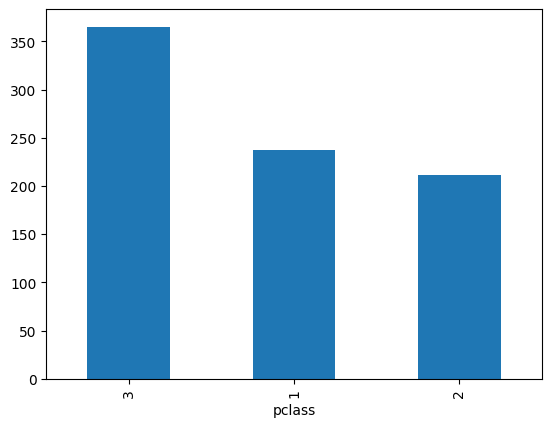

In [116]:
d1.plot(kind="bar")

In [119]:
d2=df.groupby("pclass")["survived"].value_counts()

<Axes: xlabel='pclass,survived'>

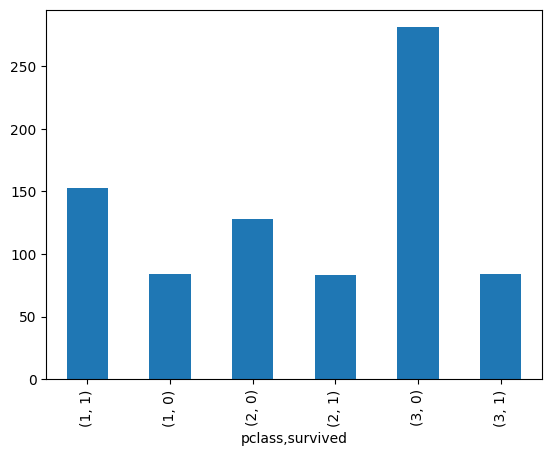

In [124]:
d2.plot(kind="bar")

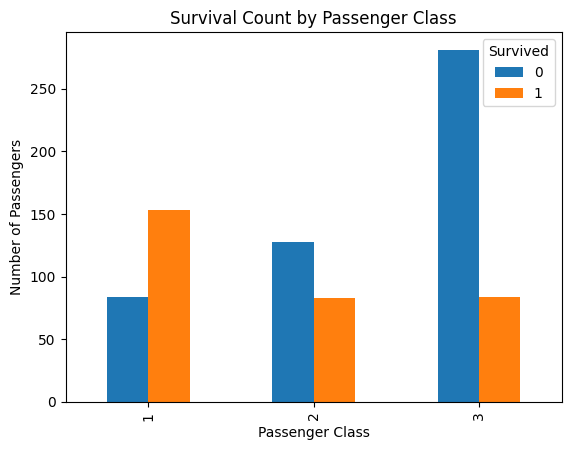

In [125]:
d2 = df.groupby("pclass", observed=True)["survived"].value_counts().unstack()

d2.plot(kind="bar")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.title("Survival Count by Passenger Class")
plt.legend(title="Survived")
plt.show()